# Employee Layoff Prediction Using Logistic Regression

## 1. Project Overview

### This project focuses on analysing employee-related data and predicting whether an employee is likely to be laid off using Logistic Regression, a supervised Machine Learning classification algorithm.

### The project involves data preprocessing, Exploratory Data Analysis (EDA), Weight of Evidence (WoE), Information Value (IV), feature selection, statistical analysis and model evaluation.

## 2. Project Objectives

### The main objectives of this project are:

### 1. To analyse employee-related data and understand the factors associated with employee layoffs.

### 2. To perform data cleaning and preprocessing to prepare the dataset for analysis.

### 3. To perform Exploratory Data Analysis (EDA) to identify patterns and relationships between employee attributes and layoff status.

### 4. To calculate Weight of Evidence (WoE) and Information Value (IV) to understand the predictive strength of independent variables.

### 5. To identify important features using statistical analysis, p-values and Variance Inflation Factor (VIF).

### 6. To build a Logistic Regression model to predict employee layoff status.

### 7. To evaluate the model performance using a Confusion Matrix, Classification Report, ROC Curve, AUC Score and KS Statistic.

### 8. To interpret the model results and identify important factors associated with employee layoffs.

## 3. Dataset Description

### 1. The dataset contains employee-related information, including department, salary, performance, tenure, management level and other employment attributes.

### 2. The dataset consists of approximately 29,194 employee records.

### 3. The target variable is `laid_off`, which indicates whether an employee has been laid off or not.

## 4. Dataset Features

| Feature Name | Description |
|---|---|
| `employee_id` | Unique identification number of each employee. |
| `department` | Department in which the employee works. |
| `cost_center_type` | Type of cost centre associated with the employee. |
| `team_wind_down` | Indicates whether the employee's team is being wound down. |
| `tenure_years` | Number of years the employee has worked in the organisation. |
| `is_recent_hire` | Indicates whether the employee is a recent hire. |
| `performance_rating` | Performance rating of the employee. |
| `on_pip` | Indicates whether the employee is on a Performance Improvement Plan (PIP). |
| `mgmt_layer` | Management layer of the employee. |
| `level` | Job level or designation of the employee. |
| `salary_k_usd` | Employee salary in thousands of US dollars. |
| `high_salary` | Indicates whether the employee belongs to the high-salary category. |
| `remote` | Indicates whether the employee works remotely. |
| `role_redundant` | Indicates whether the employee's role is redundant. |
| `laid_off` | Target variable indicating employee layoff status. |

## 5. Target Variable

### `laid_off`

### - 0 = Employee not laid off
### - 1 = Employee laid off

## 6. Independent Variables

### All employee-related attributes except `employee_id` and `laid_off` are considered independent variables.

## 7. Project Workflow

### Step 1: Import Required Libraries
### Import the libraries required for data manipulation, numerical operations, statistical analysis, and visualization.

In [1]:
import pandas as pd
import numpy as np
import os
import statsmodels.api as sm
from matplotlib import pylab
import pylab as pl

### Step 2: Load the Dataset
### Load the employee layoff dataset using Pandas and display the first few records to understand the dataset structure

In [2]:
# import dataset

os.chdir(r'C:\Users\HP\Desktop\Python for Data Science\Machine Learning\Logistic regression\LAYOFF')
data = pd.read_csv(r"C:\Users\HP\Desktop\Python for Data Science\Machine Learning\Logistic regression\LAYOFF\layoff_survival.csv")
pd.set_option('display.max_columns', None) #show all columns
data.head()

,employee_id,department,cost_center_type,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,mgmt_layer,level,salary_k_usd,high_salary,remote,role_redundant,laid_off
0,E000000,engineering,revenue,0,4.0,0,2.6,0,manager,mid,120,0,1,0,0
1,E000001,engineering,revenue,0,3.5,0,2.9,0,IC,mid,146,0,0,0,0
2,E000002,engineering,revenue,0,3.7,0,2.6,0,IC,senior,168,0,0,0,0
3,E000003,product,revenue,0,5.6,0,4.1,0,IC,staff,219,1,1,0,0
4,E000004,support,support,0,1.3,0,2.9,0,IC,junior,78,0,0,0,0


### Step 3: Data Cleaning and Initial Data Preparation
### Remove unnecessary columns such as employee_id and prepare the dataset for further analysis

In [3]:
data=data.drop(columns=["employee_id"])
data.head()

,department,cost_center_type,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,mgmt_layer,level,salary_k_usd,high_salary,remote,role_redundant,laid_off
0,engineering,revenue,0,4.0,0,2.6,0,manager,mid,120,0,1,0,0
1,engineering,revenue,0,3.5,0,2.9,0,IC,mid,146,0,0,0,0
2,engineering,revenue,0,3.7,0,2.6,0,IC,senior,168,0,0,0,0
3,product,revenue,0,5.6,0,4.1,0,IC,staff,219,1,1,0,0
4,support,support,0,1.3,0,2.9,0,IC,junior,78,0,0,0,0


### Step 4: Define WoE and IV Calculation Function
### Define a function to calculate Weight of Evidence (WoE) and Information Value (IV) for independent variables

In [4]:
import numpy as np
import pandas as pd


def iv_woe(data, target, bins=10, show_woe=False):
    # Initialize empty DataFrames to store the results
    newDF = pd.DataFrame()
    woeDF = pd.DataFrame()

    # DEFINE COLS: Get all column names from the dataset
    cols = data.columns

    # Run WOE and IV on all the independent variables
    for ivars in cols[~cols.isin([target])]:
        if (data[ivars].dtype.kind in "bifc") and (
            len(np.unique(data[ivars])) > 10
        ):
            binned_x = pd.qcut(data[ivars], bins, duplicates="drop")
            d0 = pd.DataFrame({"x": binned_x, "y": data[target]})
        else:
            d0 = pd.DataFrame({"x": data[ivars], "y": data[target]})

        d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
        d.columns = ["Cutoff", "N", "Events"]
        d["% of Events"] = np.maximum(d["Events"], 0.5) / d["Events"].sum()
        d["Non-Events"] = d["N"] - d["Events"]
        d["% of Non-Events"] = (
            np.maximum(d["Non-Events"], 0.5) / d["Non-Events"].sum()
        )
        d["WoE"] = np.log(d["% of Events"] / d["% of Non-Events"])
        d["IV"] = d["WoE"] * (d["% of Events"] - d["% of Non-Events"])
        d.insert(loc=0, column="Variable", value=ivars)

        print(
            "Information value of "
            + ivars
            + " is "
            + str(round(d["IV"].sum(), 6))
        )

        temp = pd.DataFrame(
            {"Variable": [ivars], "IV": [d["IV"].sum()]},
            columns=["Variable", "IV"],
        )
        newDF = pd.concat([newDF, temp], axis=0)
        woeDF = pd.concat([woeDF, d], axis=0)

        # Show WOE Table if requested
        if show_woe == True:
            print(d)

    # Return the dataframes after processing all variables
    return newDF, woeDF


# --- Calling the function ---
# (Ensure your 'data' DataFrame is already loaded before running this)
iv, woe = iv_woe(data=data, target="laid_off", bins=10, show_woe=True)
print(iv)
print(woe)

Information value of department is 0.364743
     Variable       Cutoff     N  Events  % of Events  Non-Events  \
0  department         data  1732     226     0.037007        1506   
1  department  engineering  7255     864     0.141477        6391   
2  department      g_and_a  2327     823     0.134763        1504   
3  department    marketing  2938     758     0.124120        2180   
4  department      product  3041     379     0.062060        2662   
5  department   recruiting  1742     669     0.109546        1073   
6  department     research  2381     899     0.147208        1482   
7  department        sales  4888     627     0.102669        4261   
8  department      support  3696     862     0.141150        2834   

   % of Non-Events       WoE        IV  
0         0.063031 -0.532528  0.013859  
1         0.267484 -0.636923  0.080257  
2         0.062947  0.761223  0.054668  
3         0.091240  0.307753  0.010119  
4         0.111413 -0.585147  0.028879  
5         0.044909 

C:\Users\HP\AppData\Local\Temp\ipykernel_30128\984600268.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
C:\Users\HP\AppData\Local\Temp\ipykernel_30128\984600268.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d = d0.groupby("x", as_index=False).agg({"y": ["count", "sum"]})
C:\Users\HP\AppData\Local\Temp\ipykernel_30128\984600268.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future 

### Step 5: Calculate and Rank Information Value (IV)
### Calculate and sort Information Value scores to identify the variables that have stronger predictive relationships with employee layoff status

In [5]:
iv = pd.DataFrame(iv)
iv.sort_values(["IV"],ascending=[0])

,Variable,IV
0,team_wind_down,1.409877
0,department,0.364743
0,cost_center_type,0.361995
0,performance_rating,0.075679
0,on_pip,0.068356
0,role_redundant,0.059379
0,is_recent_hire,0.021277
0,mgmt_layer,0.017447
0,tenure_years,0.016829
0,high_salary,0.010706


### Step 6: Outlier Analysis
### Boxplot of salary

<Axes: >

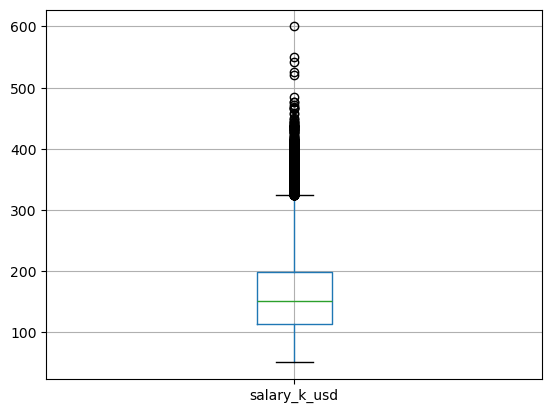

In [7]:
data.boxplot(column=["salary_k_usd"]) 

## Step7: Salary Quantile Analysis

In [9]:
# outliers with quantiles
data.salary_k_usd.quantile([0,0.01,.1,.3,.5,.7,.9,
.95,.99,.995,1])

0.000     51.0
0.010     69.0
0.100     90.0
0.300    120.0
0.500    149.0
0.700    182.0
0.900    243.0
0.950    274.0
0.990    311.0
0.995    318.0
1.000    324.0
Name: salary_k_usd, dtype: float64

## Step 8: Define IQR-Based Outlier Treatment Function
### Define a function to identify and remove salary outliers using the Interquartile Range (IQR) method

In [10]:
def outlier (data,salary_k_usd):
 Q1 = data[salary_k_usd].quantile(0.25)
 Q3 = data[salary_k_usd].quantile(0.75)
 IQR = Q3 - Q1
 data= data.loc[~((data[salary_k_usd] < (Q1 - 1.5 * IQR)) | (data[salary_k_usd] > (Q3 + 1.5 * IQR))),]
 return data

## Step 9: Visualize Salary and Tenure Distributions
### Use boxplots to visualize the distributions of salary and tenure

In [11]:
data.boxplot(column=["salary_k_usd"])
data.head(3)

,department,cost_center_type,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,mgmt_layer,level,salary_k_usd,high_salary,remote,role_redundant,laid_off
0,engineering,revenue,0,4.0,0,2.6,0,manager,mid,120,0,1,0,0
1,engineering,revenue,0,3.5,0,2.9,0,IC,mid,146,0,0,0,0
2,engineering,revenue,0,3.7,0,2.6,0,IC,senior,168,0,0,0,0


In [12]:
data.boxplot(column=["tenure_years"])
data.head(3)

,department,cost_center_type,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,mgmt_layer,level,salary_k_usd,high_salary,remote,role_redundant,laid_off
0,engineering,revenue,0,4.0,0,2.6,0,manager,mid,120,0,1,0,0
1,engineering,revenue,0,3.5,0,2.9,0,IC,mid,146,0,0,0,0
2,engineering,revenue,0,3.7,0,2.6,0,IC,senior,168,0,0,0,0


## Step 10: Descriptive Statistical Analysis
### Use describe() to understand numerical variables.

In [13]:
data.describe()

,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,salary_k_usd,high_salary,remote,role_redundant,laid_off
count,29194.000000,29194.000000,29194.000000,29194.000000,29194.000000,29194.000000,29194.000000,29194.000000,29194.000000,29194.000000
mean,0.143283,4.375838,0.069740,3.386603,0.073337,158.182640,0.229739,0.419298,0.120504,0.202507
std,0.350367,3.093732,0.254713,0.869705,0.260693,57.969584,0.420672,0.493453,0.325556,0.401875
min,0.000000,0.100000,0.000000,1.000000,0.000000,51.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.100000,0.000000,2.800000,0.000000,113.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,3.700000,0.000000,3.400000,0.000000,149.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,5.900000,0.000000,4.000000,0.000000,192.000000,0.000000,1.000000,0.000000,0.000000
max,1.000000,25.000000,1.000000,5.000000,1.000000,324.000000,1.000000,1.000000,1.000000,1.000000


## Step 11: Check Missing Values
### I checked missing values using isnull().sum() 

In [14]:
data.isnull().sum()

department            0
cost_center_type      0
team_wind_down        0
tenure_years          0
is_recent_hire        0
performance_rating    0
on_pip                0
mgmt_layer            0
level                 0
salary_k_usd          0
high_salary           0
remote                0
role_redundant        0
laid_off              0
dtype: int64

## Step 12: Encode Categorical Variables
### Logistic Regression requires numerical input, so categorical variables are converted into dummy variables

In [15]:
data = pd.get_dummies(
    data,
    columns=['department', 'cost_center_type', 'mgmt_layer', 'level'],
    drop_first=True,
    dtype=int,
)

## Step 13: Preview the Encoded Dataset
### I used head() that gives top 5 rows by default

In [16]:
data.head()

,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,salary_k_usd,high_salary,remote,role_redundant,laid_off,department_engineering,department_g_and_a,department_marketing,department_product,department_recruiting,department_research,department_sales,department_support,cost_center_type_revenue,cost_center_type_support,mgmt_layer_director,mgmt_layer_manager,level_lead,level_mid,level_senior,level_staff
0,0,4.0,0,2.6,0,120,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0
1,0,3.5,0,2.9,0,146,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0
2,0,3.7,0,2.6,0,168,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
3,0,5.6,0,4.1,0,219,1,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1
4,0,1.3,0,2.9,0,78,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0


## Step 14: Select Initial Independent Variables
### Select the initial numerical/binary variables for Logistic Regression

In [17]:
train_cols = data.loc[:, [
    'team_wind_down',
    'tenure_years',
    'is_recent_hire',
    'performance_rating',
    'on_pip',
    'salary_k_usd',
    'high_salary',
    'remote',
    'role_redundant',
]]
train_cols.head()

,team_wind_down,tenure_years,is_recent_hire,performance_rating,on_pip,salary_k_usd,high_salary,remote,role_redundant
0,0,4.0,0,2.6,0,120,0,1,0
1,0,3.5,0,2.9,0,146,0,0,0
2,0,3.7,0,2.6,0,168,0,0,0
3,0,5.6,0,4.1,0,219,1,1,0
4,0,1.3,0,2.9,0,78,0,0,0


## Step 15: Build Logistic Regression Using Statsmodels
### Add the intercept and fit the Logistic Regression model

In [18]:
import statsmodels.api as sm

train_cols = sm.add_constant(train_cols)

logit = sm.Logit(data['laid_off'], train_cols)

result = logit.fit()

result.summary()

Optimization terminated successfully.
         Current function value: 0.365881
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               laid_off   No. Observations:                29194
Model:                          Logit   Df Residuals:                    29184
Method:                           MLE   Df Model:                            9
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.2738
Time:                        22:47:26   Log-Likelihood:                -10682.
converged:                       True   LL-Null:                       -14710.
Covariance Type:            nonrobust   LLR p-value:                     0.000
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -1.1263      0.112    -10.074      0.000      -1.345      -0.907
team_wind_down         3.2609      0.043     76.108      0.000       3.177       3.345
tenure_years          -0.0230      0.006     -3.651      0.000      -0.035      -0.011
is_recent_hire         0.6324      0.066      9.564      0.000       0.503       0.762
performance_rating    -0.2977      0.023    -12.738      0.000      -0.344      -0.252
on_pip                 0.8800      0.064     13.718      0.000       0.754       1.006
salary_k_usd          -0.0021      0.001     -4.152      0.000      -0.003      -0.001
high_salary            0.6262      0.070      8.897      0.000       0.488       0.764
remote                 0.0282      0.036      0.785      0.433      -0.042       0.099
role_redundant         1.0139      0.047     21.388      0.000       0.921       1.107
======================================================================================
"""

## Step 16: Check P-values and Coefficients
### Extract p-values and coefficients

In [19]:
var = pd.DataFrame(round(result.pvalues,3)) # shows p value
var["coeff"] = result.params #coefficients
# rename columns
var.columns = ["p value","coefficients"]
var

,p value,coefficients
const,0.000,-1.126307
team_wind_down,0.000,3.260913
tenure_years,0.000,-0.023010
is_recent_hire,0.000,0.632408
performance_rating,0.000,-0.297703
on_pip,0.000,0.879989
salary_k_usd,0.000,-0.002149
high_salary,0.000,0.626206
remote,0.433,0.028159
role_redundant,0.000,1.013866


## Step 17: Calculate Z-Score
### Calculate the z-score of the coefficients

In [20]:
cov = result.cov_params()
std_err = np.sqrt(np.diag(cov))
var["z"]=result.params.values/std_err
var

,p value,coefficients,z
const,0.000,-1.126307,-10.074029
team_wind_down,0.000,3.260913,76.108178
tenure_years,0.000,-0.023010,-3.650881
is_recent_hire,0.000,0.632408,9.563667
performance_rating,0.000,-0.297703,-12.737658
on_pip,0.000,0.879989,13.717766
salary_k_usd,0.000,-0.002149,-4.151906
high_salary,0.000,0.626206,8.896787
remote,0.433,0.028159,0.784590
role_redundant,0.000,1.013866,21.387548


## Step 18: Calculate Odds Ratio
### Convert coefficients into odds ratios using the exponential function

In [21]:
np.exp(result.params)

const                  0.324229
team_wind_down        26.073320
tenure_years           0.977252
is_recent_hire         1.882137
performance_rating     0.742522
on_pip                 2.410873
salary_k_usd           0.997854
high_salary            1.870500
remote                 1.028559
role_redundant         2.756236
dtype: float64

## Step 19: Import VIF Function and Prepare for Multicollinearity Analysis
### VIF is used to detect multicollinearity among independent variables

In [22]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [23]:
import statsmodels.formula.api as smf

result = smf.logit(
    formula="""laid_off ~ team_wind_down
    + tenure_years
    + is_recent_hire
    + performance_rating
    + on_pip
    + salary_k_usd
    + high_salary
    + remote
    + role_redundant
    + department_engineering
    + department_g_and_a
    + department_marketing
    + department_product
    + department_recruiting
    + department_research
    + department_sales
    + department_support
    + cost_center_type_revenue
    + cost_center_type_support
    + mgmt_layer_director
    + mgmt_layer_manager
    + level_lead
    + level_mid
    + level_senior
    + level_staff""",
    data=data
).fit(maxiter=200)

result.summary()

Optimization terminated successfully.
         Current function value: 0.351860
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               laid_off   No. Observations:                29194
Model:                          Logit   Df Residuals:                    29170
Method:                           MLE   Df Model:                           23
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.3017
Time:                        22:48:59   Log-Likelihood:                -10272.
converged:                       True   LL-Null:                       -14710.
Covariance Type:            nonrobust   LLR p-value:                     0.000
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -0.7093   5.15e+05  -1.38e-06      1.000   -1.01e+06    1.01e+06
team_wind_down               3.1218      0.044     70.903      0.000       3.036       3.208
tenure_years                -0.0230      0.006     -3.576      0.000      -0.036      -0.010
is_recent_hire               0.6685      0.068      9.886      0.000       0.536       0.801
performance_rating          -0.3036      0.024    -12.751      0.000      -0.350      -0.257
on_pip                       0.9221      0.066     14.033      0.000       0.793       1.051
salary_k_usd                -0.0019      0.001     -2.303      0.021      -0.003      -0.000
high_salary                  0.6484      0.078      8.262      0.000       0.495       0.802
remote                       0.0289      0.037      0.789      0.430      -0.043       0.101
role_redundant               1.0467      0.048     21.615      0.000       0.952       1.142
department_engineering      -0.1586      0.093     -1.705      0.088      -0.341       0.024
department_g_and_a           0.0513   5.15e+05   9.95e-08      1.000   -1.01e+06    1.01e+06
department_marketing        -0.0534   9.95e+05  -5.37e-08      1.000   -1.95e+06    1.95e+06
department_product          -0.1414      0.105     -1.345      0.179      -0.348       0.065
department_recruiting        0.1868   5.15e+05   3.62e-07      1.000   -1.01e+06    1.01e+06
department_research          0.1662   5.15e+05   3.23e-07      1.000   -1.01e+06    1.01e+06
department_sales            -0.0553      0.097     -0.571      0.568      -0.245       0.135
department_support          -0.1961   9.95e+05  -1.97e-07      1.000   -1.95e+06    1.95e+06
cost_center_type_revenue    -0.8641   5.15e+05  -1.68e-06      1.000   -1.01e+06    1.01e+06
cost_center_type_support    -0.2495    1.1e+06  -2.27e-07      1.000   -2.15e+06    2.15e+06
mgmt_layer_director          0.7650      0.074     10.386      0.000       0.621       0.909
mgmt_layer_manager           0.3650      0.047      7.710      0.000       0.272       0.458
level_lead                  -0.1345      0.147     -0.913      0.361      -0.423       0.154
level_mid                    0.0016      0.060      0.026      0.979      -0.116       0.119
level_senior                 0.0025      0.079      0.032      0.975      -0.153       0.158
level_staff                 -0.0199      0.118     -0.169      0.865      -0.251       0.211
============================================================================================
"""

In [24]:
import statsmodels.formula.api as smf

result = smf.logit(
    formula="""laid_off ~ team_wind_down
    + tenure_years
    + is_recent_hire
    + performance_rating
    + on_pip
    + salary_k_usd
    + high_salary
    + role_redundant
    + department_engineering
    + department_g_and_a
    + department_recruiting
    + department_research
    + cost_center_type_revenue
    + mgmt_layer_director
    + mgmt_layer_manager
    + level_mid
    + level_senior
    + level_staff""",
    data=data
).fit(maxiter=200)

result.summary()

Optimization terminated successfully.
         Current function value: 0.351988
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               laid_off   No. Observations:                29194
Model:                          Logit   Df Residuals:                    29175
Method:                           MLE   Df Model:                           18
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.3014
Time:                        22:49:21   Log-Likelihood:                -10276.
converged:                       True   LL-Null:                       -14710.
Covariance Type:            nonrobust   LLR p-value:                     0.000
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -1.0393      0.119     -8.716      0.000      -1.273      -0.806
team_wind_down               3.1210      0.044     70.921      0.000       3.035       3.207
tenure_years                -0.0230      0.006     -3.573      0.000      -0.036      -0.010
is_recent_hire               0.6678      0.068      9.878      0.000       0.535       0.800
performance_rating          -0.3036      0.024    -12.753      0.000      -0.350      -0.257
on_pip                       0.9225      0.066     14.042      0.000       0.794       1.051
salary_k_usd                -0.0023      0.001     -3.830      0.000      -0.004      -0.001
high_salary                  0.6535      0.078      8.342      0.000       0.500       0.807
role_redundant               1.0452      0.048     21.594      0.000       0.950       1.140
department_engineering      -0.0859      0.055     -1.562      0.118      -0.194       0.022
department_g_and_a           0.4316      0.066      6.578      0.000       0.303       0.560
department_recruiting        0.5690      0.073      7.839      0.000       0.427       0.711
department_research          0.5480      0.065      8.451      0.000       0.421       0.675
cost_center_type_revenue    -0.5551      0.050    -11.000      0.000      -0.654      -0.456
mgmt_layer_director          0.7662      0.074     10.408      0.000       0.622       0.910
mgmt_layer_manager           0.3649      0.047      7.709      0.000       0.272       0.458
level_mid                    0.0306      0.050      0.617      0.537      -0.067       0.128
level_senior                 0.0516      0.056      0.921      0.357      -0.058       0.162
level_staff                  0.0556      0.083      0.674      0.501      -0.106       0.217
============================================================================================
"""

In [25]:
import statsmodels.formula.api as smf

result = smf.logit(
    formula="""laid_off ~ team_wind_down
    + tenure_years
    + is_recent_hire
    + performance_rating
    + on_pip
    + salary_k_usd
    + high_salary
    + role_redundant
    + department_g_and_a
    + department_recruiting
    + department_research
    + cost_center_type_revenue
    + mgmt_layer_director
    + mgmt_layer_manager""",
    data=data
).fit(maxiter=200)

result.summary()

Optimization terminated successfully.
         Current function value: 0.352045
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               laid_off   No. Observations:                29194
Model:                          Logit   Df Residuals:                    29179
Method:                           MLE   Df Model:                           14
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.3013
Time:                        22:49:37   Log-Likelihood:                -10278.
converged:                       True   LL-Null:                       -14710.
Covariance Type:            nonrobust   LLR p-value:                     0.000
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -1.0554      0.118     -8.971      0.000      -1.286      -0.825
team_wind_down               3.1210      0.044     70.932      0.000       3.035       3.207
tenure_years                -0.0228      0.006     -3.551      0.000      -0.035      -0.010
is_recent_hire               0.6673      0.068      9.874      0.000       0.535       0.800
performance_rating          -0.3029      0.024    -12.730      0.000      -0.350      -0.256
on_pip                       0.9235      0.066     14.062      0.000       0.795       1.052
salary_k_usd                -0.0020      0.001     -3.880      0.000      -0.003      -0.001
high_salary                  0.6397      0.072      8.921      0.000       0.499       0.780
role_redundant               1.0444      0.048     21.581      0.000       0.950       1.139
department_g_and_a           0.4321      0.066      6.586      0.000       0.303       0.561
department_recruiting        0.5687      0.073      7.836      0.000       0.426       0.711
department_research          0.5483      0.065      8.456      0.000       0.421       0.675
cost_center_type_revenue    -0.5913      0.045    -13.185      0.000      -0.679      -0.503
mgmt_layer_director          0.7656      0.074     10.404      0.000       0.621       0.910
mgmt_layer_manager           0.3642      0.047      7.696      0.000       0.271       0.457
============================================================================================
"""

## Step 20: P-value, Coefficient and VIF Analysis
### Analyze p-values, coefficients and Variance Inflation Factor (VIF) to assess statistical significance and multicollinearity among independent variables

In [26]:
var = pd.DataFrame(round(result.pvalues,3))# shows p value
var["coeff"] = result.params#coefficients
var.columns = ["p value","coeff"]
variables = result.model.exog #.if I had saved data as rock

### Calculate VIF for Each Independent Variable

In [27]:
# this it would have looked like rock.model.exog
vif = [variance_inflation_factor(variables, i) for i in range(variables.shape[1])]
vif 

[np.float64(1.0000000000000002),
 np.float64(1.0552373338721),
 np.float64(1.1258653950548994),
 np.float64(1.1255736750367917),
 np.float64(1.259171676572786),
 np.float64(1.2592955405068376),
 np.float64(2.837303525967413),
 np.float64(2.837773324709255),
 np.float64(1.0004500379237695),
 np.float64(1.2507721021411862),
 np.float64(1.1974931255214813),
 np.float64(1.257823814500313),
 np.float64(1.5696951525357519),
 np.float64(1.0110209171104425),
 np.float64(1.0109888935962277)]

## Combine P-values, Coefficients and VIF Scores

In [28]:
var["vif"] = vif
var ## final variables after vif

,p value,coeff,vif
Intercept,0.0,-1.055437,1.000000
team_wind_down,0.0,3.121010,1.055237
tenure_years,0.0,-0.022819,1.125865
is_recent_hire,0.0,0.667328,1.125574
performance_rating,0.0,-0.302875,1.259172
on_pip,0.0,0.923472,1.259296
salary_k_usd,0.0,-0.002044,2.837304
high_salary,0.0,0.639682,2.837773
role_redundant,0.0,1.044407,1.000450
department_g_and_a,0.0,0.432072,1.250772


## Step 21: Select Final Independent Variables
### Select the final independent variables based on the statistical analysis and multicollinearity results

In [29]:
train_cols = data.loc[:, [
    'team_wind_down',
    'tenure_years',
    'is_recent_hire',
    'performance_rating',
    'on_pip',
    'salary_k_usd',
    'high_salary',
    'role_redundant',
    'department_g_and_a',
    'department_recruiting',
    'department_research',
    'cost_center_type_revenue',
    'mgmt_layer_director',
    'mgmt_layer_manager',
]]

## Step 22: Import Scikit-learn Logistic Regression

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

In [31]:
train_cols = data.loc[:, [
    'team_wind_down',
    'tenure_years',
    'is_recent_hire',
    'performance_rating',
    'on_pip',
    'salary_k_usd',
    'high_salary',
    'role_redundant',
    'department_g_and_a',
    'department_recruiting',
    'department_research',
    'cost_center_type_revenue',
    'mgmt_layer_director',
    'mgmt_layer_manager',
]]

## Step 23: Define Input and Target Variables

In [32]:
inputData=train_cols  # ind var
outputData=data.loc[:,"laid_off"]  # dep var

In [33]:
outputData.count()

np.int64(29194)

## Step 24: Train the Logistic Regression Model
### Check model score and generate predictions

In [34]:
logit1=LogisticRegression(C=1e9, max_iter=1000)
logit1.fit(inputData,outputData)
logit1.score(inputData,outputData)

y_pred = logit1.predict(train_cols)
prob = logit1.predict_proba(train_cols)

## Step 25: Extract Predicted Layoff Probabilities
### predict_proba() gives probabilities for both classes

In [35]:
#transform the probabilities into DataFrame
# it shows probability for both

prob = pd.DataFrame(prob)
prob = prob.iloc[:,1] #showing the probability of being 1
prob = prob.reset_index()
prob.head()

,index,1
0,0,0.082732
1,1,0.051990
2,2,0.054065
3,3,0.056040
4,4,0.106908


## Step 26: Prepare Actual Target Values

In [36]:
outputData = pd.DataFrame(outputData)
outputData.head()
outputData = outputData.reset_index()
outputData = outputData.iloc[:,1]
outputData.head()

0    0
1    0
2    0
3    0
4    0
Name: laid_off, dtype: int64

## Step 27: Create Actual vs Predicted Probability DataFrame
### After that rename the columns
### Here:
### - y = actual outcome
### - p = predicted probability

In [37]:
rock = pd.concat([outputData,prob], axis=1)
rock = rock.iloc[:,[0,2]] #this line might give error, check the column index
rock.head()
df = rock.copy()
df.columns = ["y","p"]
df.head()

,y,p
0,0,0.082732
1,0,0.051990
2,0,0.054065
3,0,0.056040
4,0,0.106908


## Step 26: Evaluate Model Using Confusion Matrix
### A confusion matrix shows True Positive, True Negative, False Positive, and False Negative predictions

In [38]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
confusion_matrix(outputData,logit1.predict(inputData)) # this is experimental not required

array([[22216,  1066],
       [ 2873,  3039]])

## Step 29: Generate Classification Report
### The classification report summarizes precision, recall, F1-score, and support for each class

In [39]:
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(outputData,logit1.predict(inputData)))
print(classification_report(outputData,logit1.predict(inputData)))

[[22216  1066]
 [ 2873  3039]]
              precision    recall  f1-score   support

           0       0.89      0.95      0.92     23282
           1       0.74      0.51      0.61      5912

    accuracy                           0.87     29194
   macro avg       0.81      0.73      0.76     29194
weighted avg       0.86      0.87      0.86     29194



## Step 30: Calculate ROC Curve Values
### Calculate False Positive Rate and True Positive Rate

In [40]:
## Computing false and true positive rates

fpr, tpr,_=roc_curve(outputData,logit1.predict_proba(inputData)[:,1],drop_intermediate=False)

## Step 31: Plot ROC Curve and Calculate AUC Score
### AUC summarizes the ROC curve, where a higher AUC indicates better class discrimination

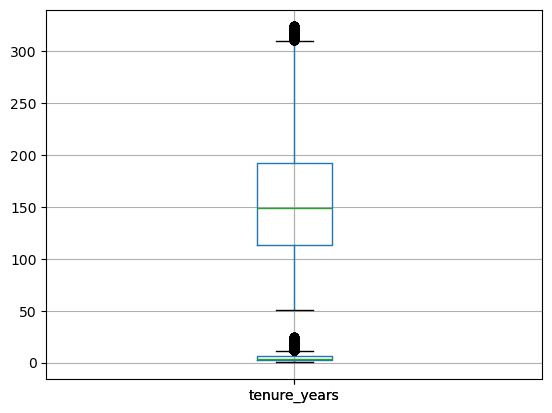

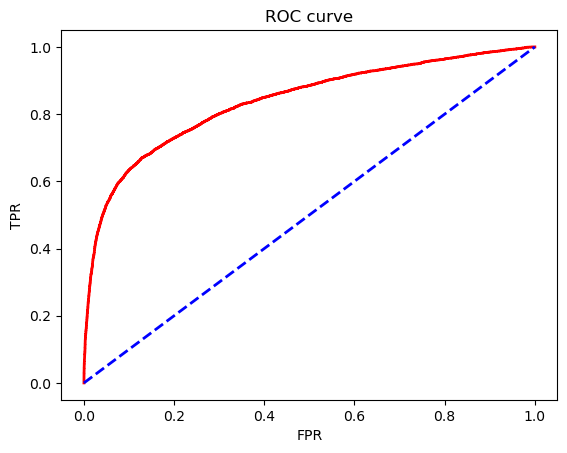

np.float64(0.8378829386858705)

In [41]:
import matplotlib.pyplot as plt
plt.figure()
##Adding the ROC
plt.plot(fpr, tpr, color='red',
 lw=2, label='ROC curve')
##Random FPR and TPR
plt.plot([0, 1], [0, 1], color='blue', lw=2, linestyle='--')
##Title and label
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC curve')
plt.savefig('ROC_CURVE.png', dpi=300, bbox_inches='tight')
plt.show()
roc_auc_score(outputData,logit1.predict_proba(inputData)[:,1])

In [42]:
df = rock.copy()
df.columns = ["y","p"]
df.head()

,y,p
0,0,0.082732
1,0,0.051990
2,0,0.054065
3,0,0.056040
4,0,0.106908


## Step 32: Calculate Kolmogorov-Smirnov (KS) Statistic
### Define the KS function
### KS statistic measures the maximum separation between the cumulative distributions of events and non-events

In [43]:
def ks(data=None,target=None, prob=None):
    data['target0'] = 1 - data[target]
    data['bucket'] = pd.qcut(data[prob].rank(method="first"), 10, labels=False)
    grouped = data.groupby('bucket', as_index = False)
    kstable = pd.DataFrame()
    kstable['min_prob'] = grouped.min()[prob]
    kstable['max_prob'] = grouped.max()[prob]
    kstable['events']   = grouped.sum()[target]
    kstable['nonevents'] = grouped.sum()['target0']
    kstable = kstable.sort_values(by="min_prob", ascending=False).reset_index(drop = True)
    kstable['event_rate'] = (kstable.events / data[target].sum()).apply('{0:.2%}'.format)
    kstable['nonevent_rate'] = (kstable.nonevents / data['target0'].sum()).apply('{0:.2%}'.format)
    kstable['cum_eventrate']=(kstable.events / data[target].sum()).cumsum()
    kstable['cum_noneventrate']=(kstable.nonevents / data['target0'].sum()).cumsum()
    kstable['KS'] = np.round(kstable['cum_eventrate']-kstable['cum_noneventrate'], 3) * 100

    #Formating
    kstable['cum_eventrate']= kstable['cum_eventrate'].apply('{0:.2%}'.format)
    kstable['cum_noneventrate']= kstable['cum_noneventrate'].apply('{0:.2%}'.format)
    kstable.index = range(1,11)
    kstable.index.rename('Decile', inplace=True)
    pd.set_option('display.max_columns', 9)
    print(kstable)
    
    #Display KS
    from colorama import Fore
    print(Fore.RED + "KS is " + str(max(kstable['KS']))+"%"+ " at decile " + str((kstable.index[kstable['KS']==max(kstable['KS'])][0])))
    return(kstable)

In [44]:
mydf = ks(data=df,target="y", prob="p")

        min_prob  max_prob  events  nonevents event_rate nonevent_rate  \
Decile                                                                   
1       0.668601  0.986980    2364        556     39.99%         2.39%   
2       0.271544  0.668533    1318       1601     22.29%         6.88%   
3       0.167916  0.271509     594       2325     10.05%         9.99%   
4       0.128084  0.167912     452       2468      7.65%        10.60%   
5       0.099352  0.128076     316       2603      5.35%        11.18%   
6       0.078895  0.099344     243       2676      4.11%        11.49%   
7       0.062837  0.078894     206       2714      3.48%        11.66%   
8       0.050877  0.062828     161       2758      2.72%        11.85%   
9       0.041034  0.050877     145       2774      2.45%        11.91%   
10      0.018189  0.041031     113       2807      1.91%        12.06%   

       cum_eventrate cum_noneventrate    KS  
Decile                                       
1             39.99

## Step 33: Create Final Prediction Dataset
### Reset indexes and combine the prediction data with the original data

In [45]:
df = rock.copy()
df.columns = ["y","p"]
df.reset_index(inplace=True)
df.head()

,index,y,p
0,0,0,0.082732
1,1,0,0.051990
2,2,0,0.054065
3,3,0,0.056040
4,4,0,0.106908


In [46]:
kane = data.copy()
kane.reset_index(inplace=True)
kane.head()

,index,team_wind_down,tenure_years,is_recent_hire,...,level_lead,level_mid,level_senior,level_staff
0,0,0,4.0,0,...,0,1,0,0
1,1,0,3.5,0,...,0,1,0,0
2,2,0,3.7,0,...,0,0,1,0
3,3,0,5.6,0,...,0,0,0,1
4,4,0,1.3,0,...,0,0,0,0


### Combine:
#### I combine the original employee information with the actual target and predicted probability to create the final prediction dataset.

In [47]:
final = pd.concat([df,kane],axis=1)
final.head()

,index,y,p,index,...,level_lead,level_mid,level_senior,level_staff
0,0,0,0.082732,0,...,0,1,0,0
1,1,0,0.051990,1,...,0,1,0,0
2,2,0,0.054065,2,...,0,0,1,0
3,3,0,0.056040,3,...,0,0,0,1
4,4,0,0.106908,4,...,0,0,0,0


## Step 34: Export Final Prediction Dataset
### I export the model results and employee-level predictions into a CSV file for further analysis

In [48]:
final.to_csv('LAYOFF_Final__Predicted.csv',index=False)

## 8. Project Summary

**Project Workflow: Employee Layoff Prediction Using Logistic Regression**

**Step 1:** Data Loading  
**Step 2:** Data Cleaning and Initial Preparation  
**Step 3:** Weight of Evidence (WoE) and Information Value (IV) Analysis  
**Step 4:** Salary Outlier Analysis  
**Step 5:** Descriptive Statistical Analysis  
**Step 6:** Missing Value Checking  
**Step 7:** Categorical Variable Encoding  
**Step 8:** Initial Feature Selection  
**Step 9:** Logistic Regression Using Statsmodels  
**Step 10:** P-value and Coefficient Analysis  
**Step 11:** Z-score and Odds Ratio Analysis  
**Step 12:** Multicollinearity Analysis Using VIF  
**Step 13:** Model Refinement and Final Feature Selection  
**Step 14:** Logistic Regression Using Scikit-learn  
**Step 15:** Model Prediction and Probability Estimation  
**Step 16:** Model Evaluation Using Confusion Matrix and Classification Report  
**Step 17:** ROC Curve and AUC Score  
**Step 18:** Kolmogorov-Smirnov (KS) Statistic  
**Step 19:** Final Prediction Dataset  
**Step 20:** Export Final Prediction Dataset to CSV